# Decoding healthy vs. unhealthy food from EEG – Rafaela's part

**Question.** From the EEG recorded while a participant looks at a food image, can we predict whether the participant judges that food **healthy** or **unhealthy**?

**Data.** FOODEEG dataset (categorisation task), preprocessed by the professor (`epoch_data.nc`: 0.5–40 Hz, average reference, 256 Hz, GEDAI cleaning), reduced to 6 subjects: sub-006, 008, 009, 013, 014, 015.

**Main finding.** The pipeline works (the response hand is decoded, AUC ≈ 0.64), but healthy vs. unhealthy stays at chance with 6 subjects × 120 trials, whatever the classifier, regularisation or smoothing. The effect reported in the paper is small and needs more data.

**Outline**
1. Loading the data
2. Understanding the structure (epochs, masks, labels)
3. Helper functions
4. Analysis 1 – fixed window (200–500 ms) and regularisation
5. Analysis 2 – time-resolved decoding
6. Analysis 3 – attempts to improve sensitivity (LDA, temporal smoothing)
7. Analysis 4 – sanity check: decoding the response hand
8. Summary and next steps

## 1. Loading the data

The reduced file (6 subjects, ≈ 0.8 GB) was created **once** from the professor's full file (13.6 GB, since deleted):

```python
ds = xr.open_dataset(".../epoch_data.nc")          # lazy: nothing is loaded into memory
names = [s + "_task-categorisation" for s in ["sub-006", "sub-008", "sub-009", "sub-013", "sub-014", "sub-015"]]
ds.sel(recording=names).load().to_netcdf(".../epoch_data_6sujets.nc")
```

We skipped sub-007 (not in the file) and sub-010/011/012 (flagged "exclude" in `participants.tsv`).

In [2]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

DATA_FILE = "/Users/rafaela.dsp/Desktop/EPFL/MA1/Machine Learning/ML_EEG_FoodImages/epoch_data_6sujets.nc"
SFREQ = 256  # samples per second

petit = xr.load_dataset(DATA_FILE)
SUBJECTS = petit.recording.values
print(SUBJECTS)

['sub-006_task-categorisation' 'sub-008_task-categorisation'
 'sub-009_task-categorisation' 'sub-013_task-categorisation'
 'sub-014_task-categorisation' 'sub-015_task-categorisation']


## 2. Understanding the data structure

For one subject, `data` has shape **(721 epochs, 64 electrodes, 705 time points)**.

- **Epoch** = a segment of the recording, from −0.25 s to 2.5 s around an event.
- Each trial is cut **twice**: around the image onset (`display`) and around the question onset (`choice`) → 360 + 360 + 1 empty = 721.
- `event_type` = the question asked after the image: `health`, `taste` or `decision` (120 each).
- `resp_choice` = the participant's answer (Yes / No) **to that question**.

**Masks used:**
- `event_name == "display"` → keep the 360 epochs where the participant **looks at the image**.
- `& event_type == "health"` → keep the 120 trials where the question was "Healthy?": only there does "Yes" mean "healthy".

**Labels (y)**: 1 = healthy (Yes to "Healthy?"), 0 = unhealthy.

In [3]:
s = petit.sel(recording="sub-006_task-categorisation")
display = s.event_name.values == "display"

print("Epoch types      :", np.unique(s.event_name.values, return_counts=True))
print("Questions        :", np.unique(s.event_type.values[display], return_counts=True))
print("Data shape       :", s["data"].shape)

health_trials = display & (s.event_type.values == "health")
print("Healthy? answers :", np.unique(s.resp_choice.values[health_trials], return_counts=True))

Epoch types      : (array(['', 'choice', 'display'], dtype='<U7'), array([  1, 360, 360]))
Questions        : (array(['decision', 'health', 'taste'], dtype='<U8'), array([120, 120, 120]))
Data shape       : (721, 64, 705)
Healthy? answers : (array(['No', 'Yes'], dtype='<U3'), array([62, 58]))


## 3. Helper functions

- `health_data` selects the 120 "Healthy?" trials of one subject (image epochs) and their labels.
- `plot_curves` plots one AUC curve per subject (grey) and their mean (blue).

In [4]:
def health_data(petit, name):
    """Return X (trials, electrodes, time points), y (1 = healthy, 0 = unhealthy) and time in seconds."""
    s = petit.sel(recording=name)
    mask = (s.event_name.values == "display") & (s.event_type.values == "health")
    X = s["data"].values[mask]
    y = (s.resp_choice.values[mask] == "Yes").astype(int)
    time = s.sample.values / SFREQ
    return X, y, time


def plot_curves(time_ms, curves, title, xlabel="Time from image onset (ms)"):
    """Plot each curve in grey and their mean in blue (a single curve is plotted in blue)."""
    curves = np.atleast_2d(curves)
    fig, ax = plt.subplots(figsize=(8, 4))
    if len(curves) > 1:
        for c in curves:
            ax.plot(time_ms, c, color="#c3c2b7", linewidth=0.8)   # each subject
    ax.plot(time_ms, curves.mean(axis=0), color="#2a78d6", linewidth=2)
    ax.axhline(0.5, color="#52514e", linewidth=0.8, linestyle="--")  # chance
    ax.axvline(0, color="#52514e", linewidth=0.8)                    # event onset
    ax.set_xlabel(xlabel)
    ax.set_ylabel("AUC (0.5 = chance)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

## 4. Analysis 1 – fixed window (200–500 ms) and regularisation

Each trial is summarised by the **mean** activity of each electrode between 200 and 500 ms after image onset (the period where the paper finds a difference) → X of shape (120, 64).

Classifier: `StandardScaler` + `LogisticRegression` (L2 / ridge penalty, strength set by `C`; smaller `C` = stronger penalty), 5-fold cross-validation, score = AUC (0.5 = chance).

We run it for several values of `C` to check whether stronger or weaker regularisation helps. `C = 1` is the scikit-learn default.

In [15]:
def decode_sub(name, petit, start=0.2, end=0.5, C=1.0):
    """Mean AUC (5 folds) on the activity averaged over [start, end] seconds."""
    X, y, time = health_data(petit, name)
    window = (time >= start) & (time <= end)
    X_mean = X[:, :, window].mean(axis=2)          # (120, 64)

    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C))
    scores = cross_val_score(clf, X_mean, y, cv=5, scoring="roc_auc")
    return scores.mean()



C_values = [0.001, 0.01, 0.1, 1, 10]

for c in C_values:
    window_scores = []                                   # reset for each C
    for name in SUBJECTS:
        auc = decode_sub(name, petit, C=c)               # pass C to the function
        window_scores.append(auc)
    print(f"C = {c:<6} : mean AUC = {np.mean(window_scores):.3f}   "
          f"(per subject: {np.round(window_scores, 3)})")

C = 0.001  : mean AUC = 0.495   (per subject: [0.634 0.332 0.498 0.521 0.597 0.385])
C = 0.01   : mean AUC = 0.507   (per subject: [0.665 0.382 0.479 0.562 0.573 0.378])
C = 0.1    : mean AUC = 0.513   (per subject: [0.684 0.447 0.394 0.612 0.521 0.417])
C = 1      : mean AUC = 0.512   (per subject: [0.638 0.43  0.417 0.616 0.499 0.472])
C = 10     : mean AUC = 0.502   (per subject: [0.599 0.4   0.47  0.58  0.478 0.488])


**Results (17–19 Nov)**

| C | sub-006 | sub-008 | sub-009 | sub-013 | sub-014 | sub-015 | **Mean** |
|---|---|---|---|---|---|---|---|
| 0.001 | 0.634 | 0.332 | 0.498 | 0.521 | 0.597 | 0.385 | **0.495** |
| 0.01 | 0.665 | 0.382 | 0.479 | 0.562 | 0.573 | 0.378 | **0.507** |
| 0.1 | 0.684 | 0.447 | 0.394 | 0.612 | 0.521 | 0.417 | **0.513** |
| 1 (default) | 0.638 | 0.430 | 0.417 | 0.616 | 0.499 | 0.472 | **0.512** |
| 10 | 0.599 | 0.400 | 0.470 | 0.580 | 0.478 | 0.488 | **0.502** |

**Interpretation**
- All means are between 0.495 and 0.513: **≈ chance**, with no trend across `C` → regularisation is not the limiting factor.
- With 120 trials (24 tested per fold), a single score easily fluctuates by ±0.1; a score < 0.5 is noise, not "anti-decoding". The same subject moves a lot between `C` values (sub-008: 0.33 → 0.45), another sign that we are mostly measuring noise.
- With `C = 10` scikit-learn prints a `ConvergenceWarning` (the optimiser hit its iteration limit; warnings removed from the output above). Harmless here; `max_iter=1000` would silence it.

## 5. Analysis 2 – time-resolved decoding

Instead of averaging over 200–500 ms, we train **one classifier per time point** between −100 and 1000 ms (282 time points, one every ≈ 3.9 ms) → one AUC curve per subject.

In [6]:
def auc_curve(subjects, petit, tmin=-0.1, tmax=1.0):
    """Return (mean curve, per-subject curves (n_subjects, n_times), time in ms)."""
    curves = []
    for name in subjects:
        X, y, time = health_data(petit, name)
        window = (time >= tmin) & (time <= tmax)
        X = X[:, :, window]                           # (120, 64, 282)

        clf = make_pipeline(StandardScaler(), LogisticRegression())
        curve = []
        for t in range(X.shape[2]):
            scores = cross_val_score(clf, X[:, :, t], y, cv=5, scoring="roc_auc")
            curve.append(scores.mean())
        curves.append(curve)
        print(f"{name[:7]} done")

    curves = np.array(curves)
    return curves.mean(axis=0), curves, time[window] * 1000


mean_time, curves_time, time_ms = auc_curve(SUBJECTS, petit)   # ≈ 2 min

sub-006 done
sub-008 done
sub-009 done
sub-013 done
sub-014 done
sub-015 done


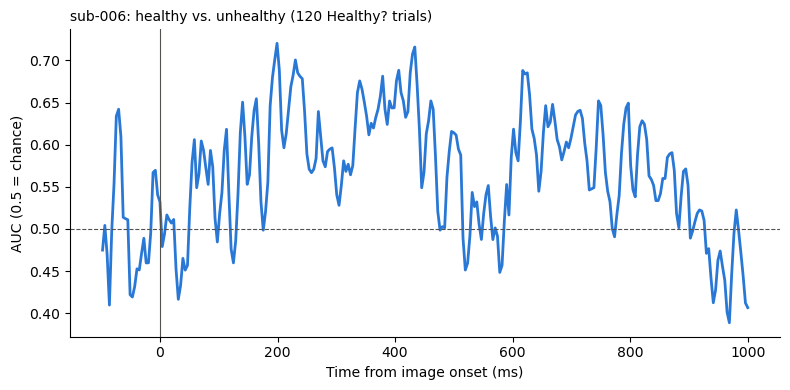

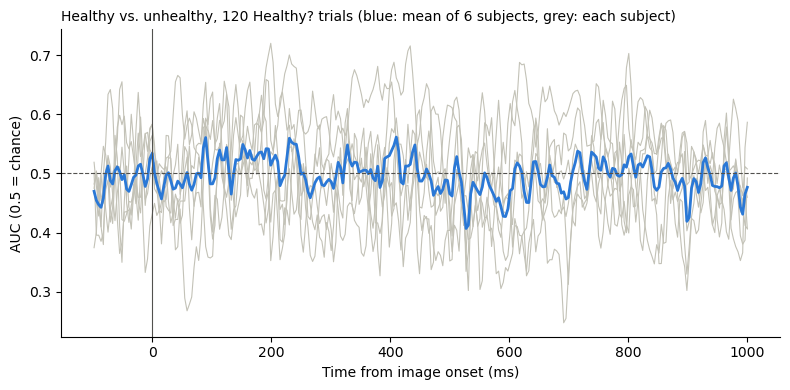

In [7]:
plot_curves(time_ms, curves_time[0], "sub-006: healthy vs. unhealthy (120 Healthy? trials)")
plot_curves(time_ms, curves_time, "Healthy vs. unhealthy, 120 Healthy? trials (blue: mean of 6 subjects, grey: each subject)")

In [10]:
# Summary for the Excel sheet: mean AUC of each subject between 150 and 600 ms
window = (time_ms >= 150) & (time_ms <= 600)
for name, auc in zip(SUBJECTS, curves_time[:, window].mean(axis=1)):
    print(f"{name[:7]} : {auc:.3f}")

print(f"Max AUC of the mean curve : {mean_time.max():.3f} at {time_ms[mean_time.argmax()]:.0f} ms")

sub-006 : 0.595
sub-008 : 0.441
sub-009 : 0.455
sub-013 : 0.519
sub-014 : 0.515
sub-015 : 0.469
Max AUC of the mean curve : 0.562 at 410 ms


**Results (17 Nov)**

| | sub-006 | sub-008 | sub-009 | sub-013 | sub-014 | sub-015 | **Mean** |
|---|---|---|---|---|---|---|---|
| Mean AUC 150–600 ms | 0.595 | 0.441 | 0.455 | 0.519 | 0.515 | 0.469 | **0.499** |

Peak of the mean curve: 0.562 at 410 ms.

**Interpretation**
- sub-006 alone: above 0.5 most of the time between 150 and 850 ms, but the noise before image onset already reaches 0.64, so single peaks are not convincing.
- Mean of 6 subjects: close to 0.5 everywhere, small bump at 100–400 ms that is not distinguishable from noise. Subjects vary a lot.

## 6. Analysis 3 – attempts to improve sensitivity

### 6a. LDA with shrinkage

Same time-resolved analysis with `LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")`: a linear classifier that takes the noise and the correlations between electrodes into account; the shrinkage stabilises this estimate when there are few trials (≈ 96 training trials for 64 electrodes).

In [8]:
def auc_curve_lda(subjects, petit, tmin=-0.1, tmax=1.0):
    """Return (mean curve, per-subject curves (n_subjects, n_times), time in ms)."""
    curves = []
    for name in subjects:
        X, y, time = health_data(petit, name)
        window = (time >= tmin) & (time <= tmax)
        X = X[:, :, window]                           # (120, 64, 282)

        clf = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"))
        curve = []
        for t in range(X.shape[2]):
            scores = cross_val_score(clf, X[:, :, t], y, cv=5, scoring="roc_auc")
            curve.append(scores.mean())
        curves.append(curve)
        print(f"{name[:7]} done")

    curves = np.array(curves)
    return curves.mean(axis=0), curves, time[window] * 1000


mean_time_corr, curves_time_corr, time_ms_corr = auc_curve_lda(SUBJECTS, petit)   # ≈ 2 min

sub-006 done
sub-008 done
sub-009 done
sub-013 done
sub-014 done
sub-015 done


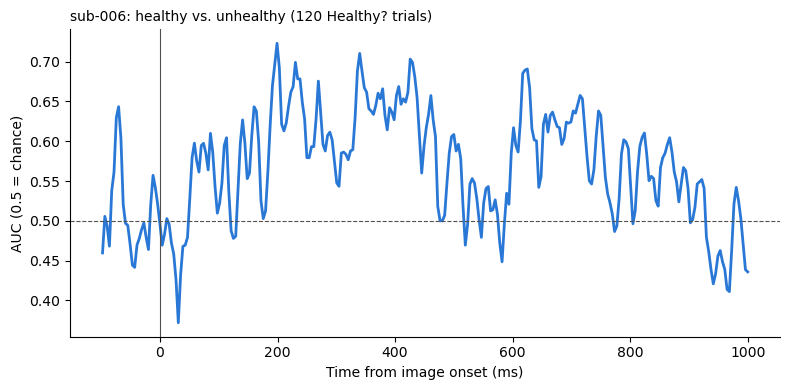

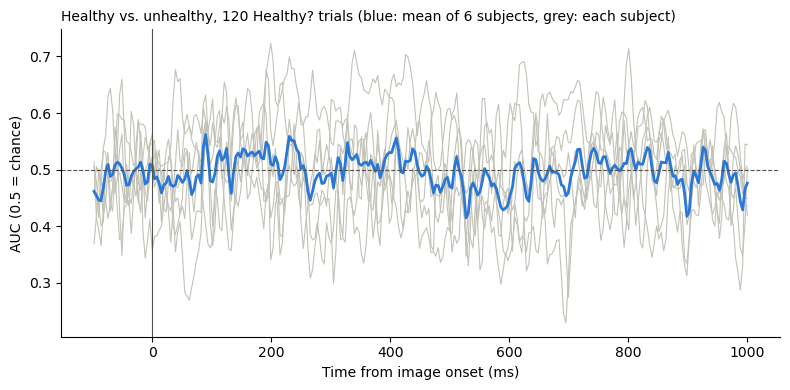

In [9]:
plot_curves(time_ms_corr, curves_time_corr[0], "sub-006: healthy vs. unhealthy (120 Healthy? trials)")
plot_curves(time_ms_corr, curves_time_corr, "Healthy vs. unhealthy, 120 Healthy? trials (blue: mean of 6 subjects, grey: each subject)")

**Result:** very similar to logistic regression (mean ≈ chance). Both classifiers are linear; when there is almost no signal, neither can find one.

### 6b. Temporal smoothing (≈ 20 ms)

At each time point, the data are averaged over 5 neighbouring samples (t−2 … t+2) before decoding, to reduce noise.

sub-006 done
sub-008 done
sub-009 done
sub-013 done
sub-014 done
sub-015 done
(6, 278) (278,)


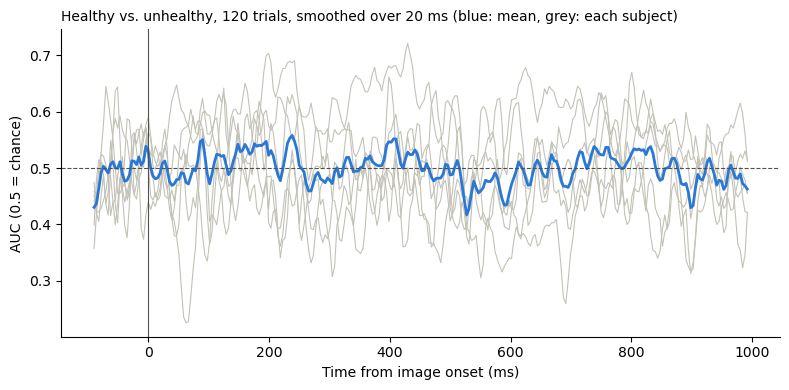

In [13]:
def auc_curve_smoothed(subjects, petit, tmin=-0.1, tmax=1.0, half_width=2):
    """Same as auc_curve, but at each time point the data are averaged
    over t-half_width ... t+half_width (half_width=2 -> 5 samples ≈ 20 ms)."""
    curves = []
    for name in subjects:
        X, y, time = health_data(petit, name)
        window = (time >= tmin) & (time <= tmax)
        X = X[:, :, window]                                  # (120, 64, 282)
        n_times = X.shape[2]

        clf = make_pipeline(StandardScaler(), LogisticRegression())
        curve = []
        # Start and stop half_width positions from the edges, so t-2 is never negative
        for t in range(half_width, n_times - half_width):
            # 1. Small slice around t: positions t-2, t-1, t, t+1, t+2 (end excluded -> t+3)
            X_slice = X[:, :, t - half_width : t + half_width + 1]   # (120, 64, 5)
            # 2. Average over time -> back to (120, 64)
            X_t = X_slice.mean(axis=2)
            # 3. ONE decoding per time point, on the averaged data
            scores = cross_val_score(clf, X_t, y, cv=5, scoring="roc_auc")
            curve.append(scores.mean())

        curves.append(curve)                                 # once per subject
        print(f"{name[:7]} done")

    curves = np.array(curves)
    time_ms = time[window] * 1000
    time_ms = time_ms[half_width : n_times - half_width]     # remove the same edge points
    return curves.mean(axis=0), curves, time_ms


mean_smooth, curves_smooth, time_smooth = auc_curve_smoothed(SUBJECTS, petit)   # ≈ 2 min
print(curves_smooth.shape, time_smooth.shape)   # expected: (6, 278) (278,)

plot_curves(time_smooth, curves_smooth,
            "Healthy vs. unhealthy, 120 trials, smoothed over 20 ms (blue: mean, grey: each subject)")

**Result:** no improvement. The data were already low-pass filtered at 40 Hz, so they are already smooth at the 20 ms scale; the remaining noise is the trial-to-trial variability, which only more trials can reduce.

## 7. Analysis 4 – sanity check: decoding the response hand

**Goal:** check that the code works by decoding a **strong** effect: the hand used to answer (left / right), on the `choice` epochs (time-locked to the question onset).

- The key assigned to "Yes" changes randomly on every trial → the hand says nothing about the content of the answer; it is a pure motor effect.
- Motor preparation appears ≈ 200–300 ms before the key press, and response times are ≈ 0.6–2 s after the question. A first try with a window up to 600 ms stayed at chance (too early); the window therefore goes up to **1500 ms**.
- All 360 trials are kept: the epochs are not cut at the response, so there are no missing values.

In [11]:
def decode_hand(subjects, petit, tmin=-0.1, tmax=1.5):
    """Time-resolved left / right decoding on the "choice" epochs."""
    curves = []
    for name in subjects:
        s = petit.sel(recording=name)

        choice_mask = s.event_name.values == "choice"          # all trials, time-locked to the question
        X = s["data"].values[choice_mask]
        hand = s.resp_position.values[choice_mask]
        y = (hand == "Right").astype(int)                      # 1 = right, 0 = left

        time = s.sample.values / SFREQ
        window = (time >= tmin) & (time <= tmax)
        X = X[:, :, window]

        complete = ~np.isnan(X).any(axis=(1, 2)) & np.isin(hand, ["Left", "Right"])
        X, y = X[complete], y[complete]
        print(f"{name[:7]} : {len(y)} trials kept, {y.sum()} right")

        clf = make_pipeline(StandardScaler(), LogisticRegression())
        curve = [cross_val_score(clf, X[:, :, t], y, cv=5, scoring="roc_auc").mean()
                 for t in range(X.shape[2])]
        curves.append(curve)

    curves = np.array(curves)
    return curves.mean(axis=0), curves, time[window] * 1000


mean_hand, curves_hand, time_hand = decode_hand(SUBJECTS, petit)   # ≈ 3–4 min

sub-006 : 360 trials kept, 177 right
sub-008 : 360 trials kept, 190 right
sub-009 : 360 trials kept, 187 right
sub-013 : 360 trials kept, 176 right
sub-014 : 360 trials kept, 185 right
sub-015 : 360 trials kept, 176 right


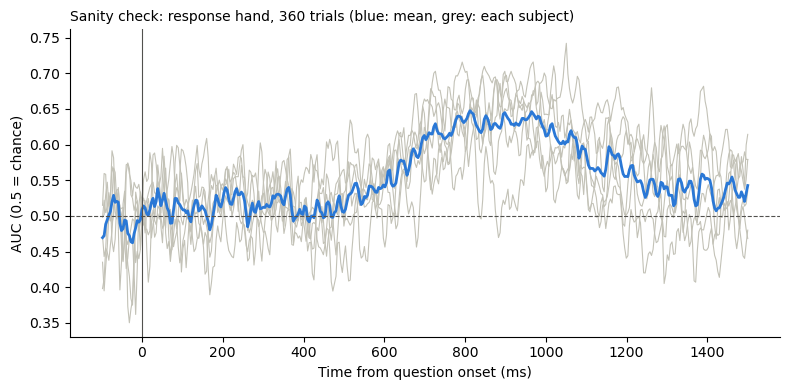

In [12]:
plot_curves(time_hand, curves_hand, "Sanity check: response hand, 360 trials (blue: mean, grey: each subject)",
            xlabel="Time from question onset (ms)")

**Result (19 Nov)**
- ≈ 0.5 until ≈ 500 ms (participants read the question and find where "Yes" is).
- **Clear rise from ≈ 550 ms**, plateau at **≈ 0.62–0.65 between 750 and 1050 ms**, then decrease after ≈ 1100 ms (most participants have answered).
- **All 6 subjects rise together** (some up to 0.7).

→ **The pipeline works.** Healthy vs. unhealthy staying at chance is a sensitivity issue, not a bug.

**Link with the project question.** For such a strong motor effect, 0.64 is modest and the peak is very spread out (600–1100 ms). Response times vary from trial to trial, so motor preparation never happens at the same moment: averaging over trials smears and flattens the decoding. This is an example of a "time-jittered" short-lived process looking like a long one — exactly what aligning trials on HMP events is meant to address.

## 8. Summary and next steps

| Analysis | Trials | Mean AUC | Conclusion |
|---|---|---|---|
| Window 200–500 ms, LogisticRegression (C = 1) | 120 | 0.512 | ≈ chance |
| Window 200–500 ms, C from 0.001 to 10 | 120 | 0.495–0.513 | regularisation does not help |
| Time-resolved, LogisticRegression (mean 150–600 ms) | 120 | 0.499 | ≈ chance, small bump at 100–400 ms |
| Time-resolved, LDA shrinkage | 120 | ≈ chance | no improvement |
| Time-resolved, smoothed over 20 ms | 120 | ≈ chance | no improvement (data already filtered at 40 Hz) |
| **Sanity check: response hand** | 360 | **peak ≈ 0.64 (750–1050 ms)** | **pipeline works** |

**Conclusion.** With 6 subjects and 120 "Healthy?" trials per subject, healthy vs. unhealthy cannot be decoded above chance, whatever the classifier, regularisation or smoothing. The paper detects a small effect with ≈ 110 subjects. The limiting factor is the **amount of data**.

**Next steps**
1. 360 trials per subject with labels copied per image (Ali's version, cross-validation grouped by image).
2. More subjects (20–30), loading one subject at a time.
3. Chance-level control (shuffled labels) to quantify the noise level.
4. Temporal generalisation (King & Dehaene), starting with the response hand, where there is a real signal → new notebook.
5. L1 (lasso) not tested, unlikely to help given the spatially distributed EEG signal